# Dados e Aprendizagem Automática 26/27
### Part V

## **II - Decision Tree using Incidents Dataset**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
incid = pd.read_csv('incidents.csv', na_filter=False)

**EDA**

In [3]:
incid.head()

,city_name,magnitude_of_delay,delay_in_seconds,affected_roads,record_date,luminosity,avg_temperature,avg_atm_pressure,avg_humidity,avg_wind_speed,avg_precipitation,avg_rain,incidents
0,Guimaraes,UNDEFINED,0,",",2021-03-15 23:00,DARK,12.0,1013.0,70.0,1.0,0.0,Sem Chuva,None
1,Guimaraes,UNDEFINED,385,"N101,",2021-12-25 18:00,DARK,12.0,1007.0,91.0,1.0,0.0,Sem Chuva,None
2,Guimaraes,UNDEFINED,69,",",2021-03-12 15:00,LIGHT,14.0,1025.0,64.0,0.0,0.0,Sem Chuva,Low
3,Guimaraes,MAJOR,2297,"N101,R206,N105,N101,N101,N101,N101,N101,N101,N...",2021-09-29 09:00,LIGHT,15.0,1028.0,75.0,1.0,0.0,Sem Chuva,Very_High
4,Guimaraes,UNDEFINED,0,"N101,N101,N101,N101,N101,",2021-06-13 11:00,LIGHT,27.0,1020.0,52.0,1.0,0.0,Sem Chuva,High


In [4]:
incid.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   city_name           5000 non-null   str    
 1   magnitude_of_delay  5000 non-null   str    
 2   delay_in_seconds    5000 non-null   int64  
 3   affected_roads      5000 non-null   str    
 4   record_date         5000 non-null   str    
 5   luminosity          5000 non-null   str    
 6   avg_temperature     5000 non-null   float64
 7   avg_atm_pressure    5000 non-null   float64
 8   avg_humidity        5000 non-null   float64
 9   avg_wind_speed      5000 non-null   float64
 10  avg_precipitation   5000 non-null   float64
 11  avg_rain            5000 non-null   str    
 12  incidents           5000 non-null   str    
dtypes: float64(5), int64(1), str(7)
memory usage: 507.9 KB


Drop columns that do not bring value

In [5]:
incid.drop(['affected_roads'], axis = 1, inplace = True)
incid.drop(['avg_precipitation'], axis = 1, inplace = True)
incid.drop('city_name',axis=1,inplace=True)
incid.dropna(inplace=True)

Factorization

In [6]:
incid['incidents'] = pd.factorize(incid['incidents'])[0] + 1
incid['magnitude_of_delay'] = pd.factorize(incid['magnitude_of_delay'])[0] + 1
incid['luminosity'] = pd.factorize(incid['luminosity'])[0] + 1
incid['avg_rain'] = pd.factorize(incid['avg_rain'])[0] + 1

In [7]:
incid['record_date'] = pd.to_datetime(incid['record_date'], format = '%Y-%m-%d %H:%M', errors='coerce')

In [9]:
incid.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   magnitude_of_delay  5000 non-null   int64         
 1   delay_in_seconds    5000 non-null   int64         
 2   record_date         5000 non-null   datetime64[us]
 3   luminosity          5000 non-null   int64         
 4   avg_temperature     5000 non-null   float64       
 5   avg_atm_pressure    5000 non-null   float64       
 6   avg_humidity        5000 non-null   float64       
 7   avg_wind_speed      5000 non-null   float64       
 8   avg_rain            5000 non-null   int64         
 9   incidents           5000 non-null   int64         
dtypes: datetime64[us](1), float64(4), int64(5)
memory usage: 390.8 KB


In [10]:
incid.head()

,magnitude_of_delay,delay_in_seconds,record_date,luminosity,avg_temperature,avg_atm_pressure,avg_humidity,avg_wind_speed,avg_rain,incidents
0,1,0,2021-03-15 23:00:00,1,12.0,1013.0,70.0,1.0,1,1
1,1,385,2021-12-25 18:00:00,1,12.0,1007.0,91.0,1.0,1,1
2,1,69,2021-03-12 15:00:00,2,14.0,1025.0,64.0,0.0,1,2
3,2,2297,2021-09-29 09:00:00,2,15.0,1028.0,75.0,1.0,1,3
4,1,0,2021-06-13 11:00:00,2,27.0,1020.0,52.0,1.0,1,4


<Axes: >

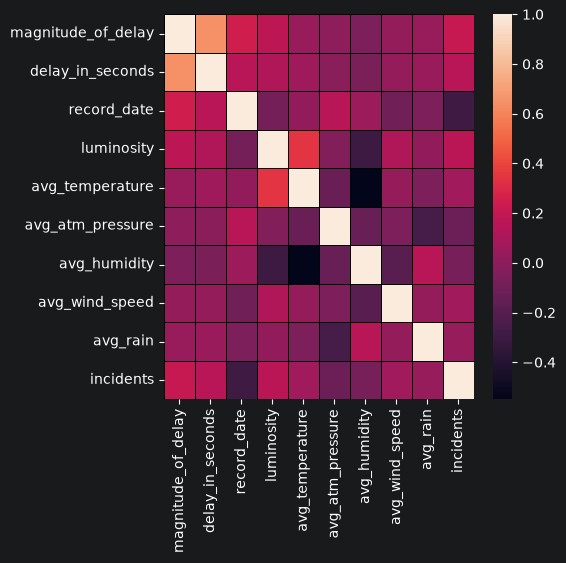

In [11]:
fig = plt.figure(figsize = (5,5))
incidents_corr = incid.corr( method = 'pearson')
sns.heatmap(incidents_corr, linecolor='black', linewidths=0.5)

- <em>magnitude_of_delay</em> and <em>delay_in_seconds</em>
- <em>magnitude_of_delay</em> and <em>record_date</em>
- <em>avg_humidity</em> and <em>luminosity<em>

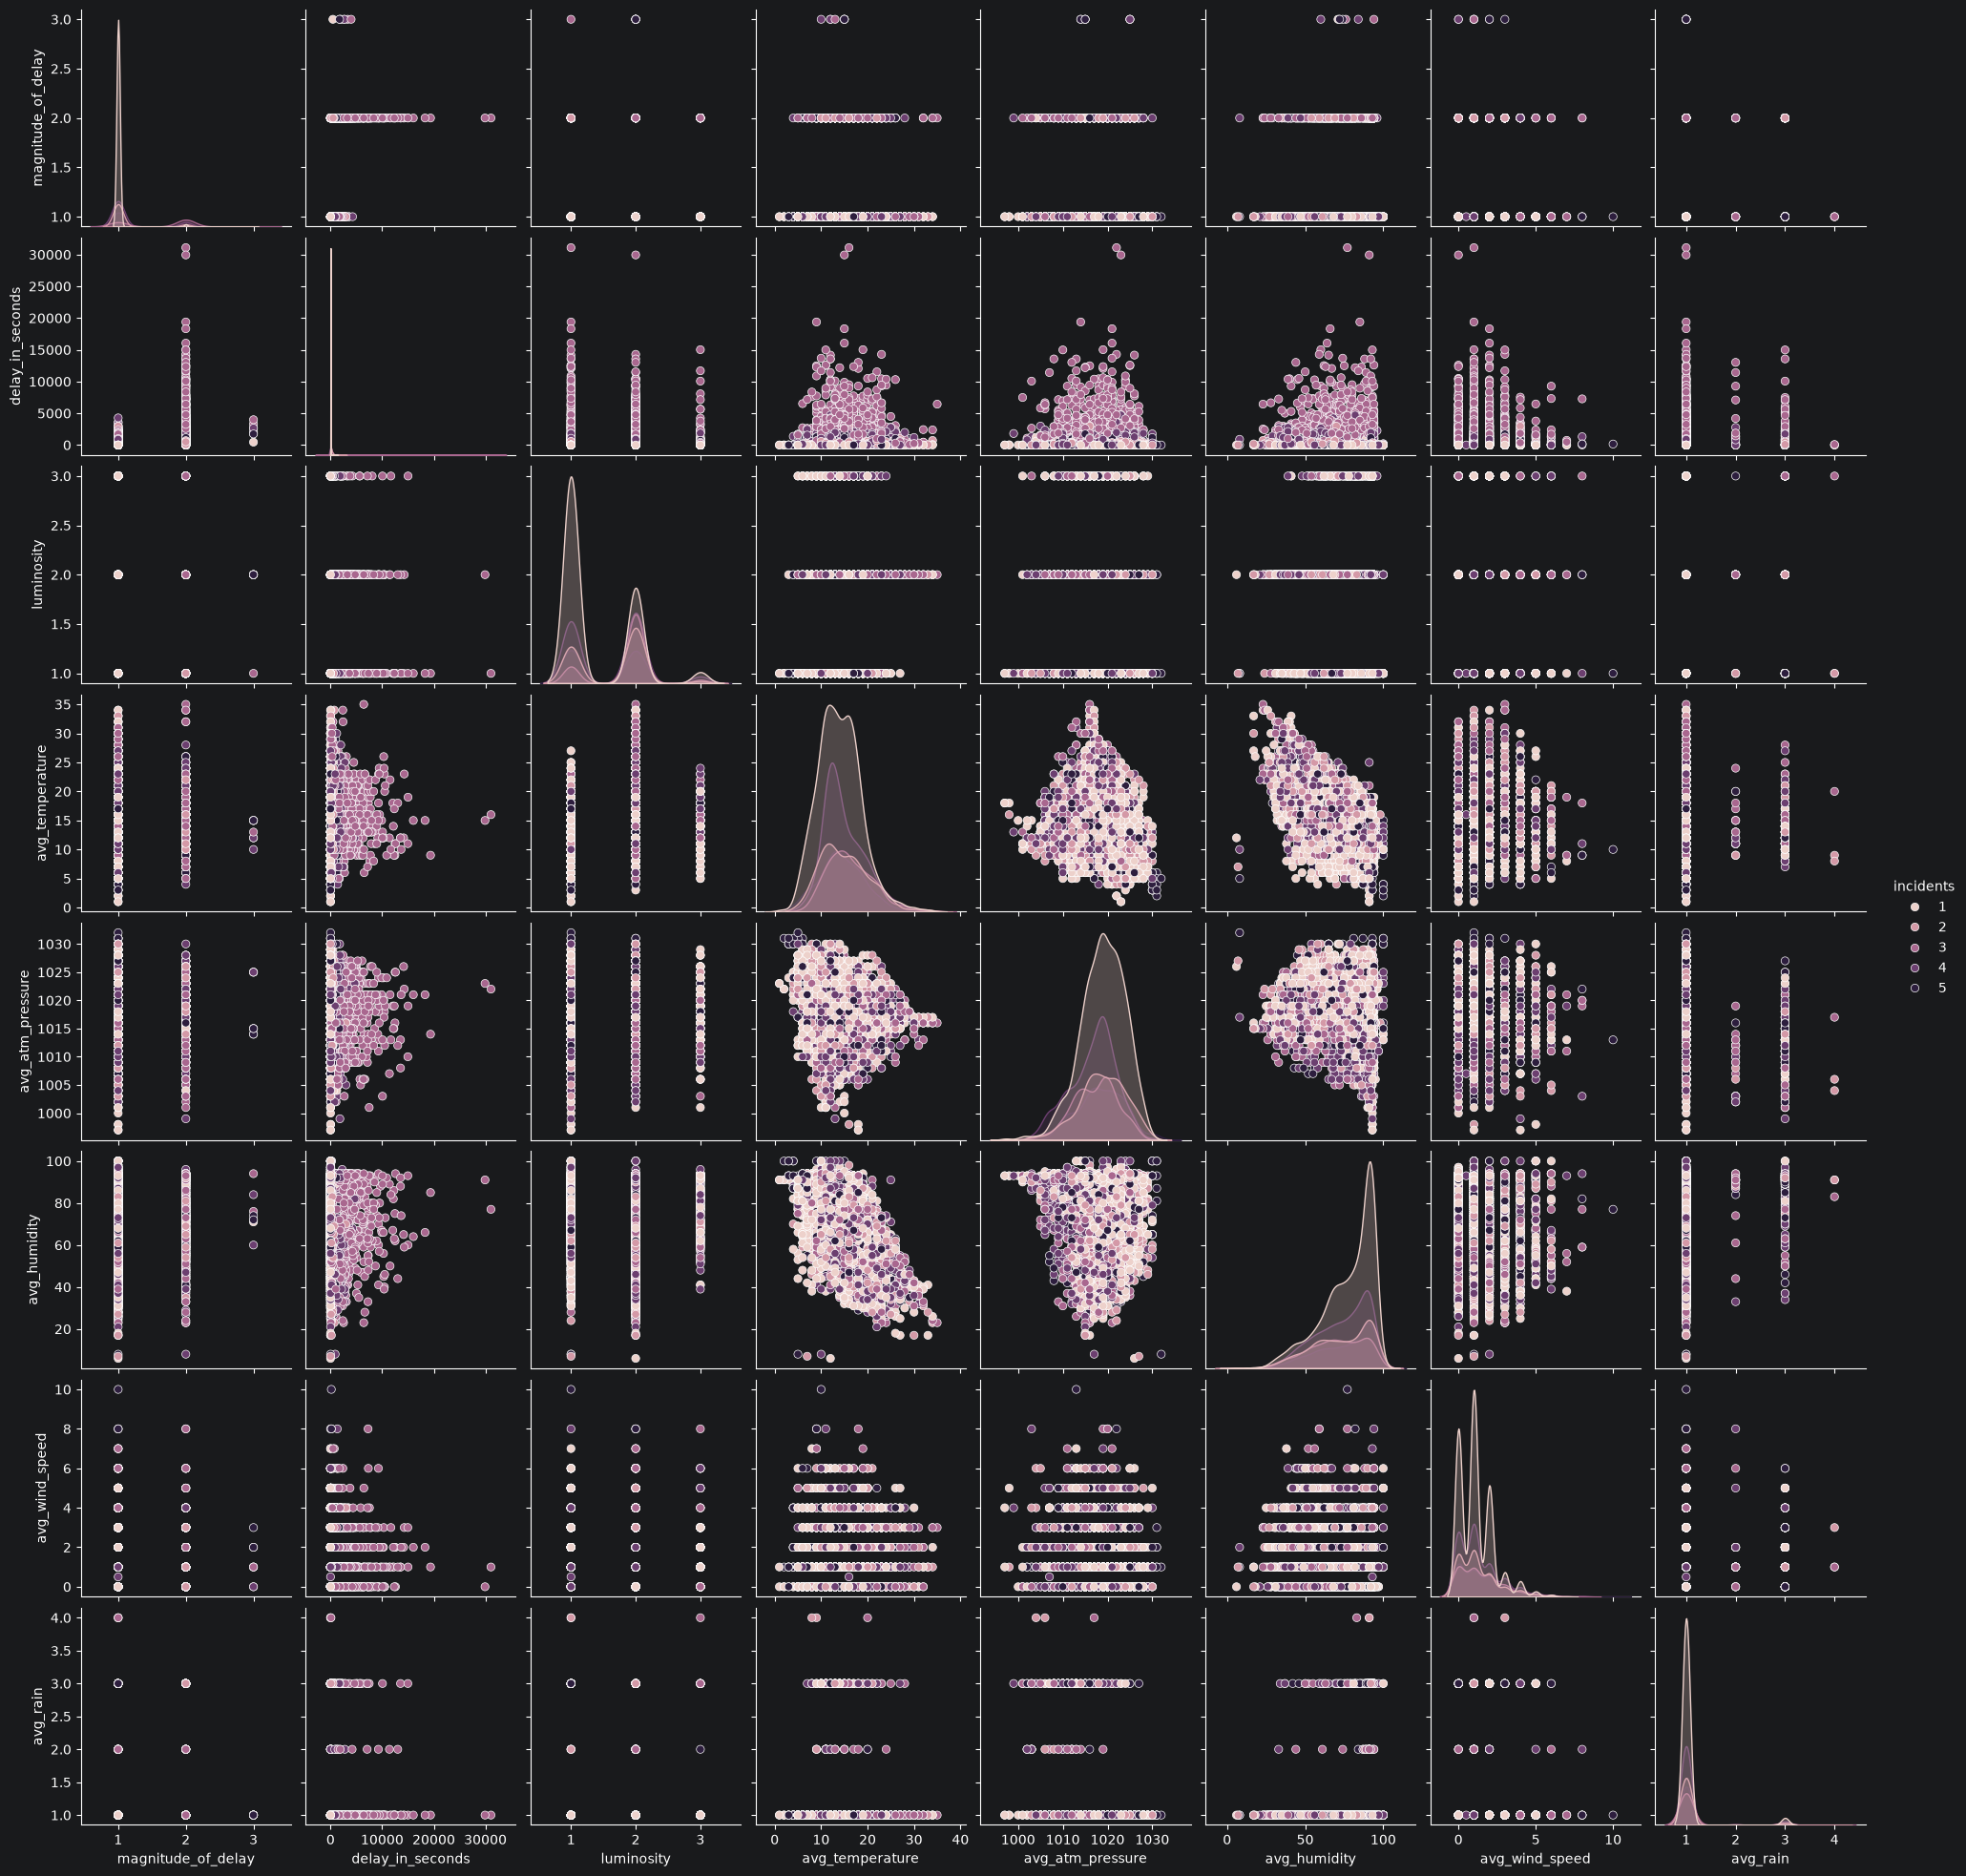

In [12]:
sns_plot = sns.pairplot(incid, hue="incidents")
sns_plot.savefig('pp.png')

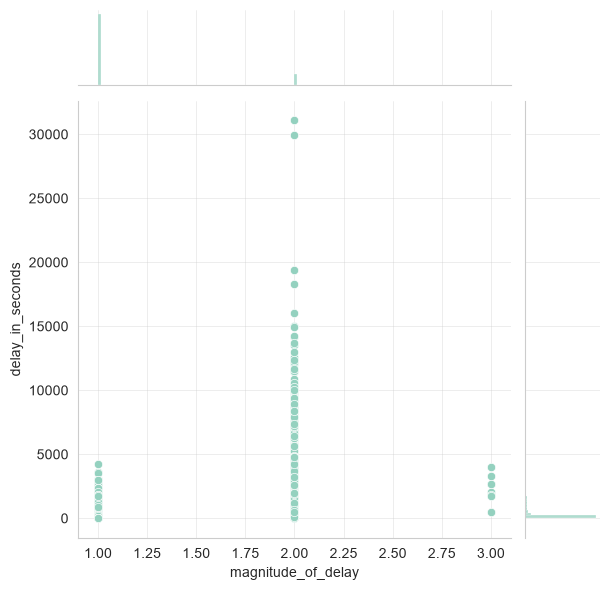

In [13]:
sns.set_palette("GnBu_d")
sns.set_style('whitegrid')
sns.jointplot(x='magnitude_of_delay', y='delay_in_seconds', data=incid)

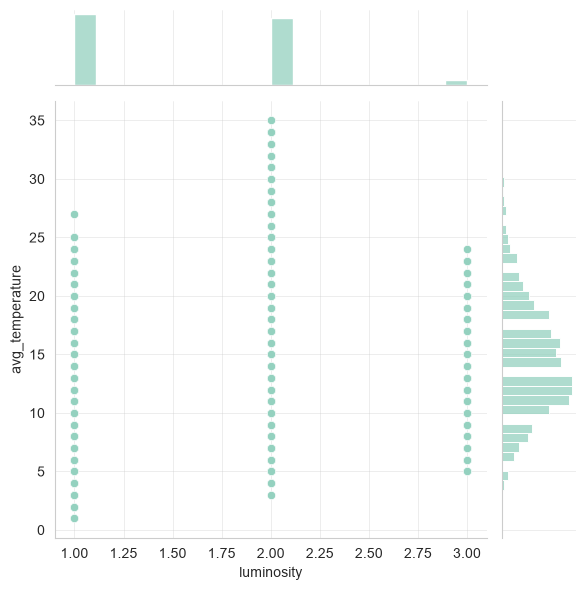

In [14]:
sns.jointplot(x='luminosity', y='avg_temperature', data=incid)

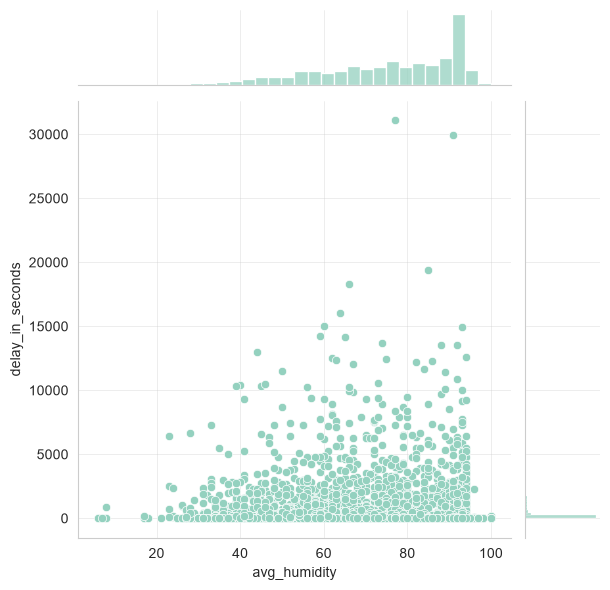

In [15]:
sns.jointplot(x='avg_humidity', y='delay_in_seconds', data=incid)

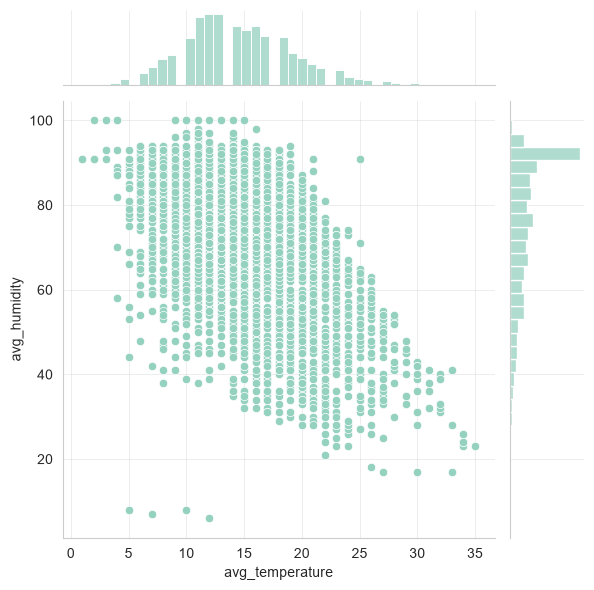

In [16]:
sns.jointplot(x='avg_temperature', y='avg_humidity', data=incid)

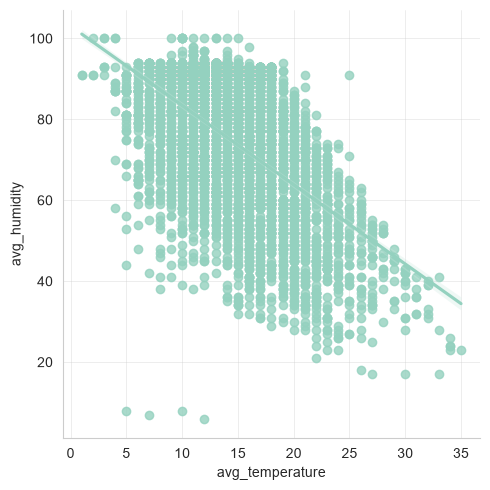

In [17]:
sns.lmplot(x='avg_temperature', y='avg_humidity', data=incid)

*Split the data*

In [18]:
from sklearn.model_selection import train_test_split

In [19]:
X = incid.drop(['record_date', 'incidents'], axis = 1)
y = incid['incidents']

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=2022)

*Train the model*

In [21]:
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

<code>sklearn.tree.DecisionTreeClassifier(*, criterion='gini', splitter='best', max_depth=None, min_samples_split=2, min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features=None, random_state=None, max_leaf_nodes=None, min_impurity_decrease=0.0, class_weight=None, ccp_alpha=0.0, monotonic_cst=None)</code>

In [22]:
dt_model = DecisionTreeClassifier(random_state=2022)

In [23]:
dt_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",2022
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

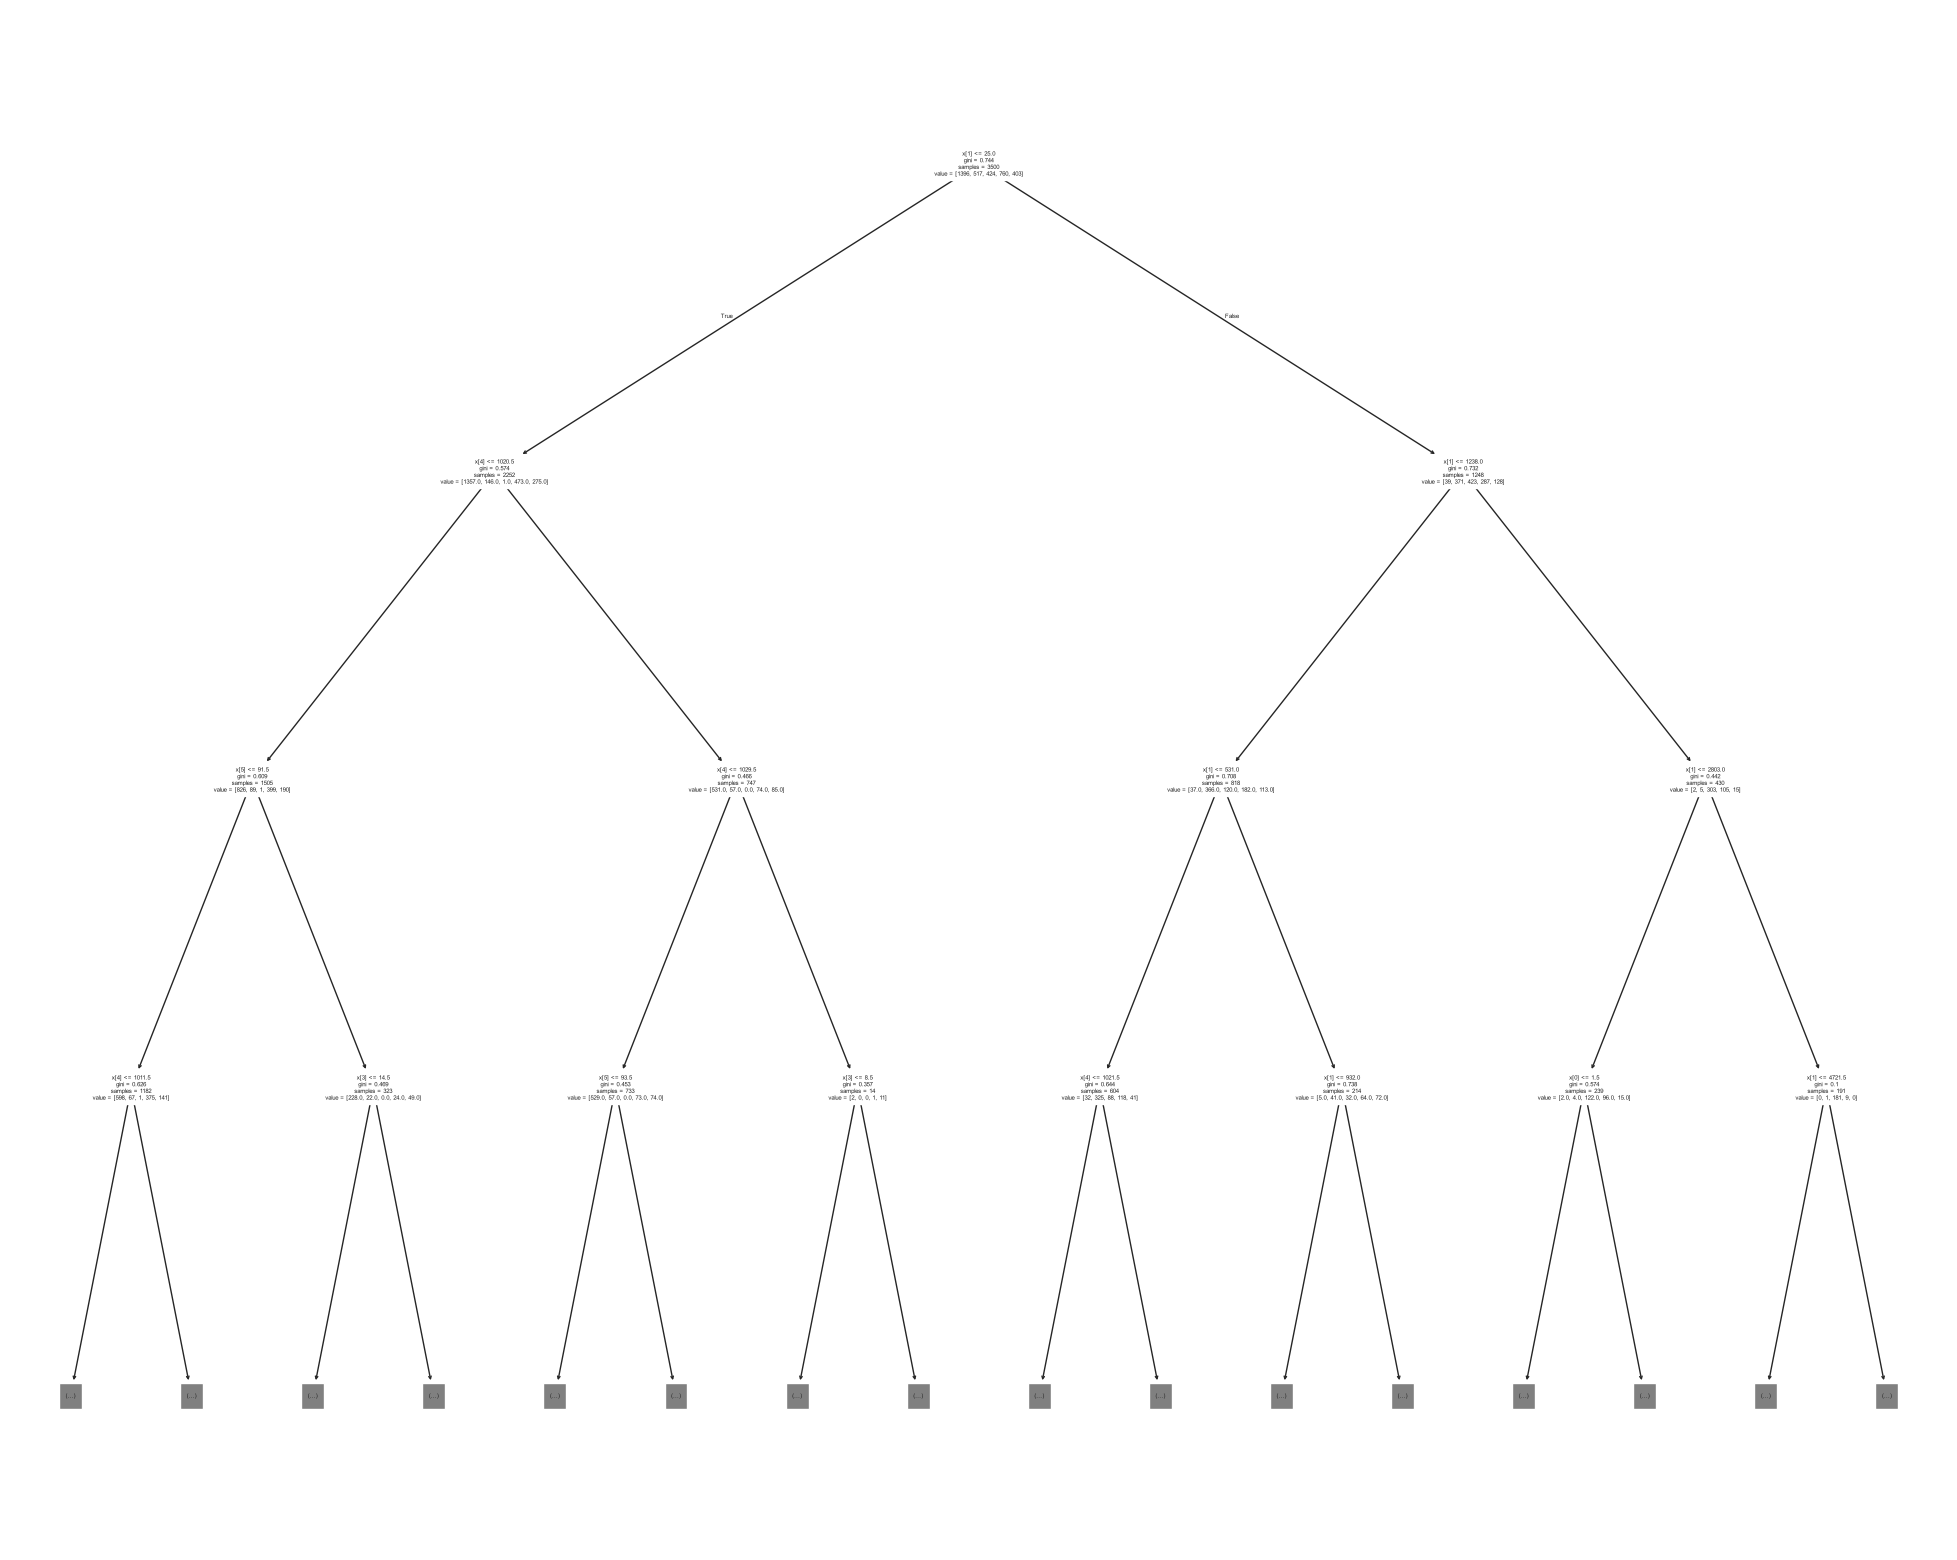

In [24]:
fig = plt.figure(figsize=(25, 20))
tree.plot_tree(dt_model, max_depth = 3)
plt.show()

fig.savefig("dt_plot.png")

In [25]:
text_representation = tree.export_text(dt_model)
print(text_representation)

with open("dt_text.log", "w") as fout:
    fout.write(text_representation)

|--- feature_1 <= 25.00
|   |--- feature_4 <= 1020.50
|   |   |--- feature_5 <= 91.50
|   |   |   |--- feature_4 <= 1011.50
|   |   |   |   |--- feature_3 <= 15.50
|   |   |   |   |   |--- feature_3 <= 11.50
|   |   |   |   |   |   |--- feature_6 <= 1.50
|   |   |   |   |   |   |   |--- feature_4 <= 1002.00
|   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |   |--- feature_4 >  1002.00
|   |   |   |   |   |   |   |   |--- feature_3 <= 10.50
|   |   |   |   |   |   |   |   |   |--- feature_2 <= 1.50
|   |   |   |   |   |   |   |   |   |   |--- feature_7 <= 1.50
|   |   |   |   |   |   |   |   |   |   |   |--- truncated branch of depth 6
|   |   |   |   |   |   |   |   |   |   |--- feature_7 >  1.50
|   |   |   |   |   |   |   |   |   |   |   |--- truncated branch of depth 3
|   |   |   |   |   |   |   |   |   |--- feature_2 >  1.50
|   |   |   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |   |   |--- feature_3 >  10.50
|   |   |   |   |   |   |  

*Predictions*

In [26]:
dt_predictions = dt_model.predict(X_test)

In [27]:
print(dt_predictions)

[2 2 1 ... 5 2 4]


*Model Evaluation*

In [28]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

In [29]:
print(classification_report(y_test, dt_predictions))

              precision    recall  f1-score   support

           1       0.75      0.74      0.74       632
           2       0.58      0.55      0.56       201
           3       0.72      0.73      0.73       179
           4       0.46      0.49      0.47       313
           5       0.40      0.42      0.41       175

    accuracy                           0.62      1500
   macro avg       0.58      0.58      0.58      1500
weighted avg       0.62      0.62      0.62      1500



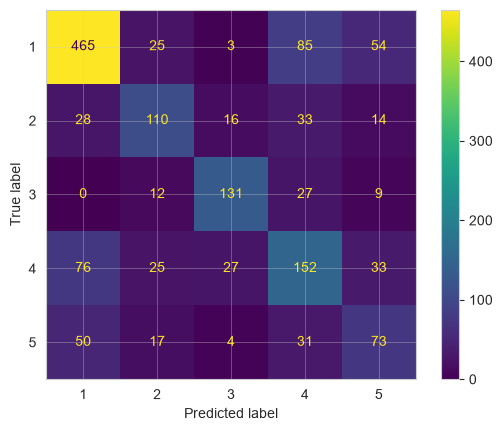

In [30]:
ConfusionMatrixDisplay.from_predictions(y_test, dt_predictions)
plt.show()

## **III - Hyperparamenter tuning with GridSearch**

<code>sklearn.model_selection.GridSearchCV(estimator, param_grid, *, scoring=None, n_jobs=None, refit=True, cv=None, verbose=0, pre_dispatch='2*n_jobs', error_score=nan, return_train_score=False)</code>

In [33]:
from sklearn.model_selection import GridSearchCV

*Depth of the tree and number of leaves obtained from the previous model*

In [31]:
print(dt_model.get_depth())
print(dt_model.get_n_leaves())

24
1189


*Hyperparameters to test: **criterion** and **max_depth***

In [34]:
param_grid_dt = {'criterion': ['gini', 'entropy',], 'max_depth': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]}
estimator_dt = DecisionTreeClassifier(random_state=2022)
grid_dt = GridSearchCV(estimator_dt, param_grid_dt, refit=True, verbose=2)

In [35]:
grid_dt.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END ........................criterion=gini, max_depth=1; total time=   0.0s
[CV] END ........................criterion=gini, max_depth=1; total time=   0.0s
[CV] END ........................criterion=gini, max_depth=1; total time=   0.0s
[CV] END ........................criterion=gini, max_depth=1; total time=   0.0s
[CV] END ........................criterion=gini, max_depth=1; total time=   0.0s
[CV] END ........................criterion=gini, max_depth=2; total time=   0.0s
[CV] END ........................criterion=gini, max_depth=2; total time=   0.0s
[CV] END ........................criterion=gini, max_depth=2; total time=   0.0s
[CV] END ........................criterion=gini, max_depth=2; total time=   0.0s
[CV] END ........................criterion=gini, max_depth=2; total time=   0.0s
[CV] END ........................criterion=gini, max_depth=3; total time=   0.0s
[CV] END ........................criterion=gini

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...om_state=2022)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [1, 2, ...]}"
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother case

Best estimator and hyperparameters

In [36]:
grid_dt.best_estimator_

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",2022
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

*Model evaluation*

In [37]:
print(classification_report(y_test, grid_dt.predict(X_test)))

              precision    recall  f1-score   support

           1       0.68      0.93      0.78       632
           2       0.55      0.71      0.62       201
           3       0.79      0.75      0.77       179
           4       0.52      0.22      0.31       313
           5       0.40      0.16      0.23       175

    accuracy                           0.64      1500
   macro avg       0.59      0.55      0.54      1500
weighted avg       0.61      0.64      0.60      1500



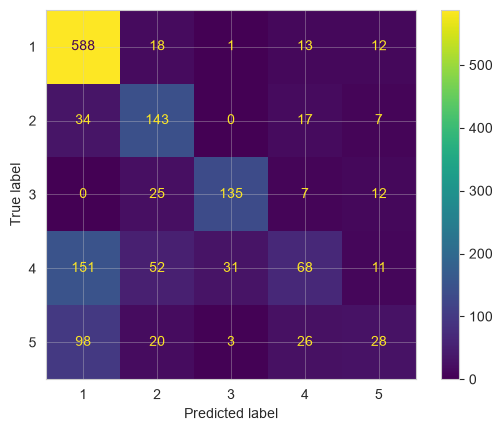

In [38]:
ConfusionMatrixDisplay.from_predictions(y_test, grid_dt.predict(X_test))
plt.show()

## **IV - Decision Tree Pruning**

*Tree max depth*

In [39]:
max_depth = dt_model.get_depth()
max_depth

24

*Pré-pruning: **max_depth***

In [40]:
param_grid_pru = {'max_depth': [max_depth for max_depth in range(1, max_depth + 1)]}
estimator_pru = DecisionTreeClassifier(random_state=2022)
max_depth_gs = GridSearchCV(estimator_pru, param_grid_pru)

In [41]:
max_depth_gs.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...om_state=2022)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [1, 2, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with 

*Best hyperparameters and estimator configuration*

In [42]:
max_depth_gs.best_params_

{'max_depth': 6}

In [43]:
max_depth_tree = max_depth_gs.best_estimator_
print(max_depth_tree)

DecisionTreeClassifier(max_depth=6, random_state=2022)


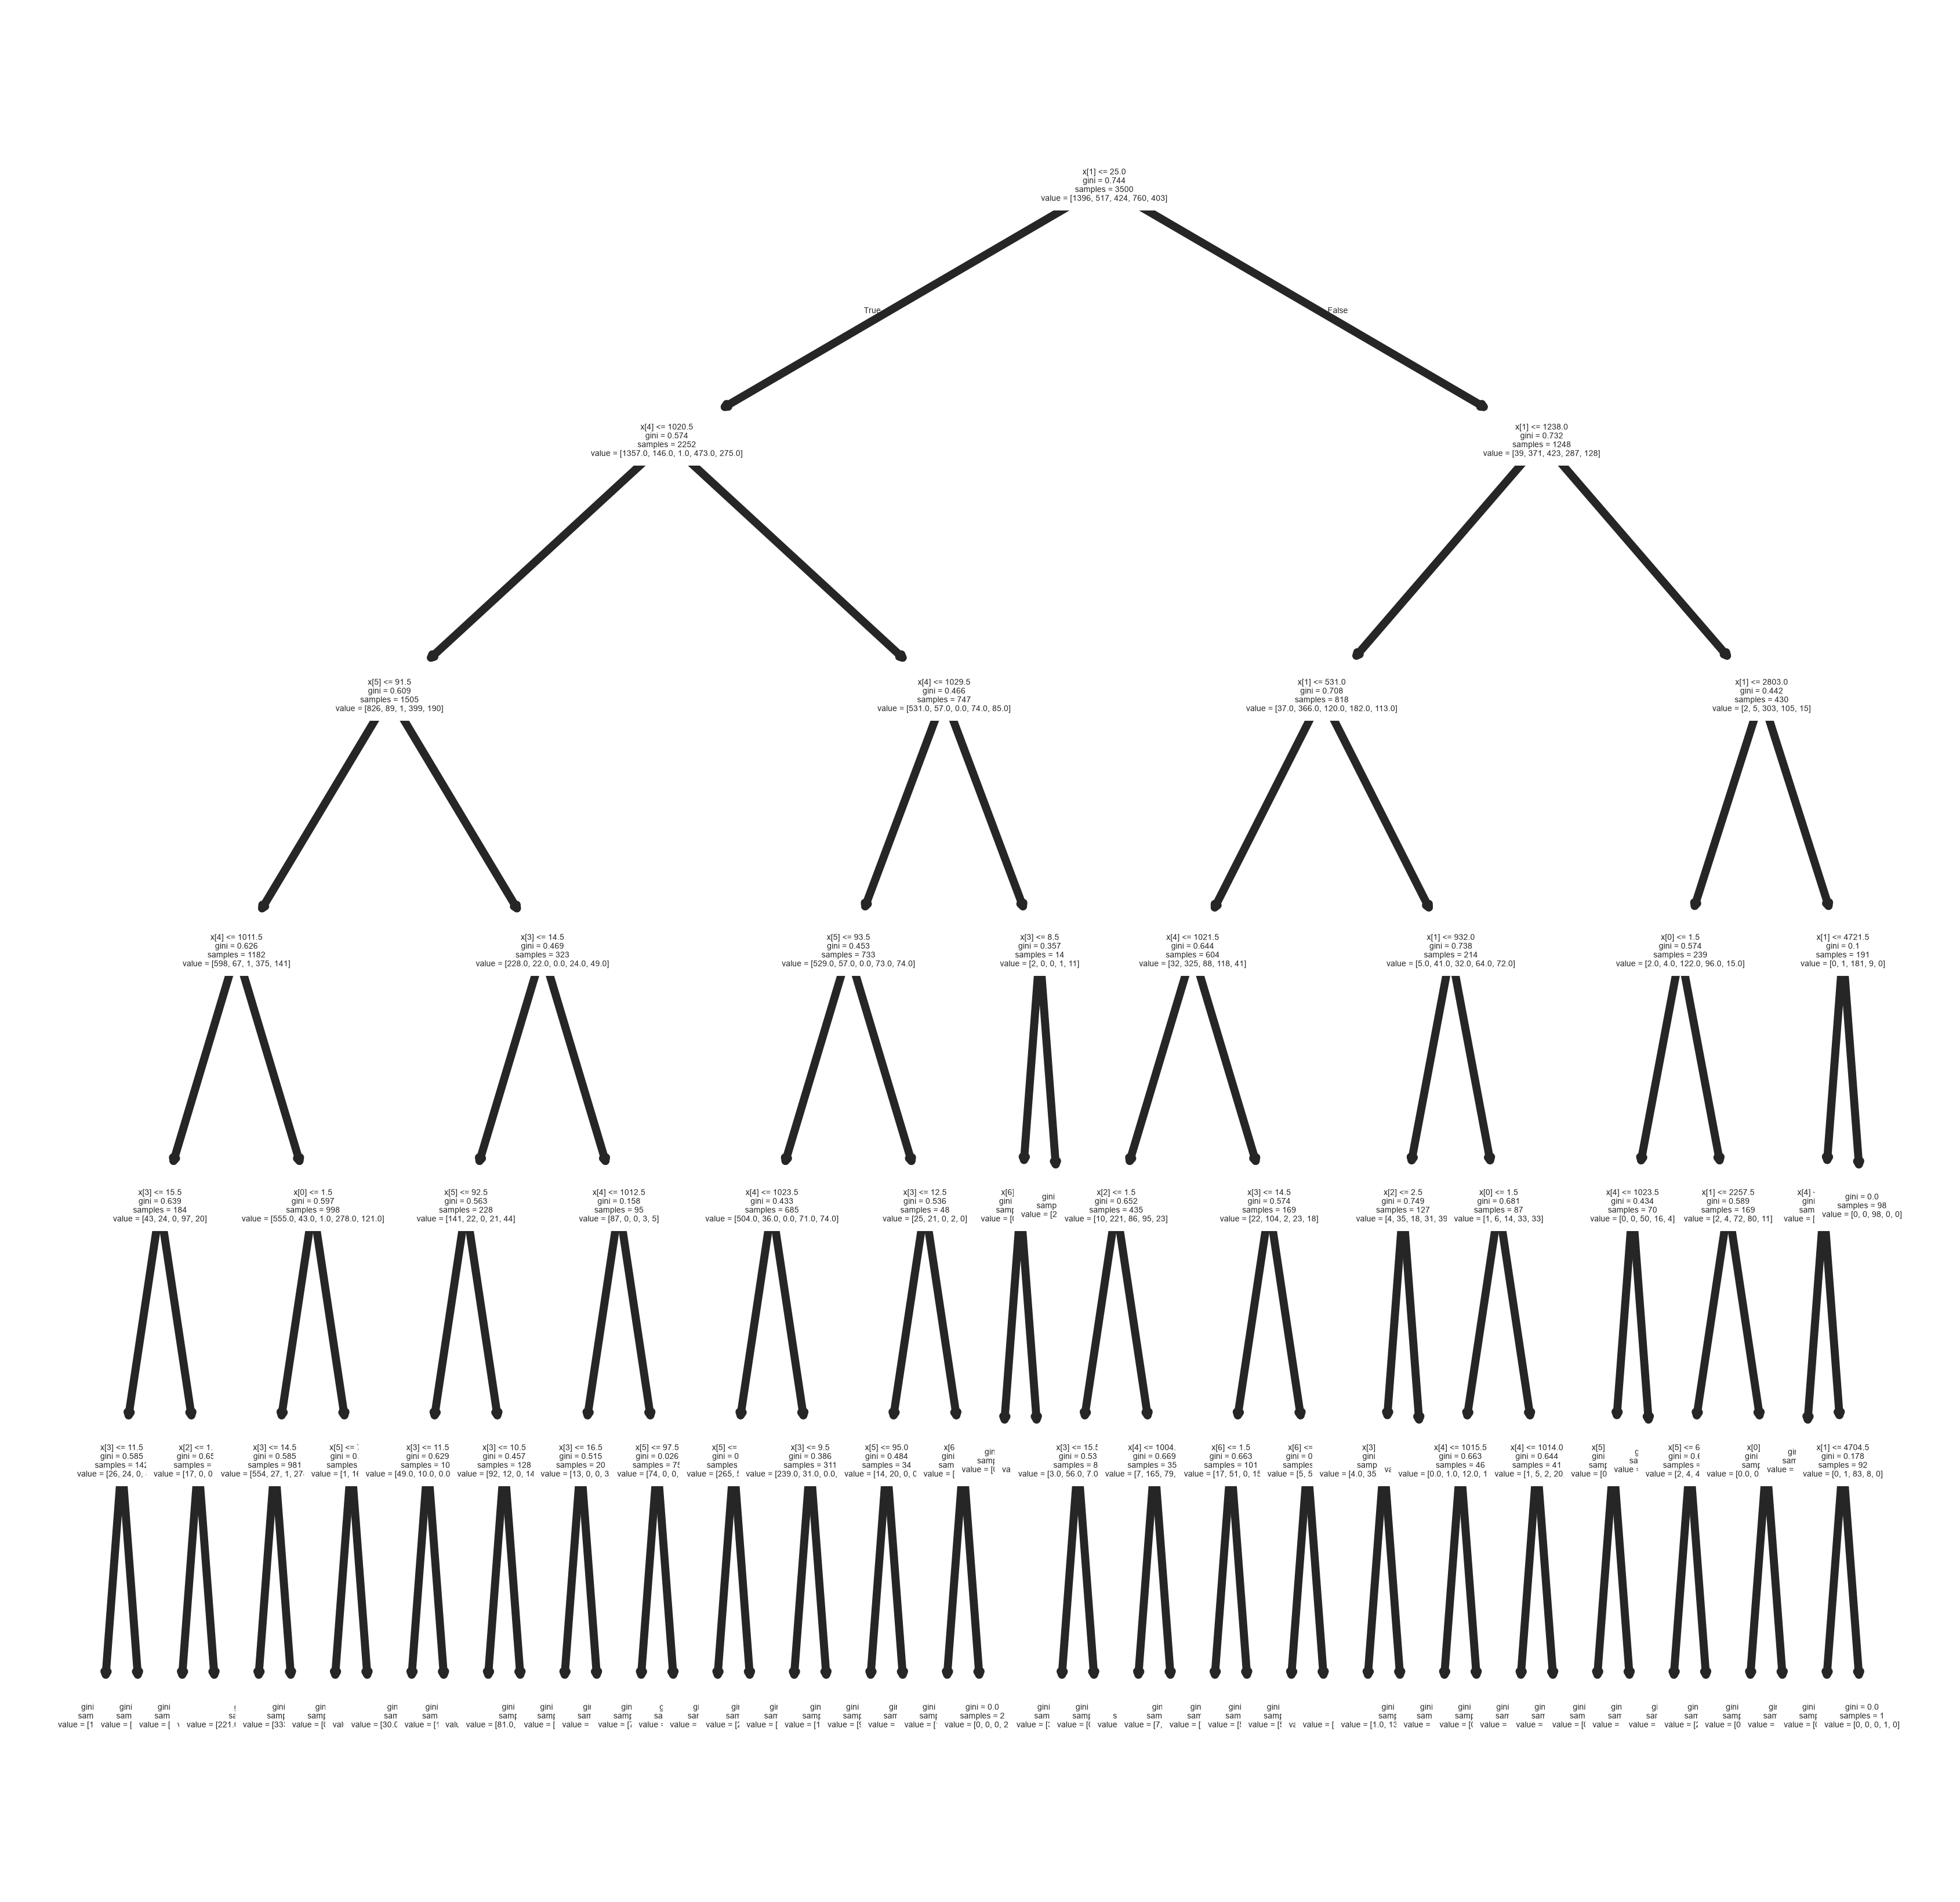

In [44]:
fig = plt.figure(figsize=(4,4), dpi=1000)
tree.plot_tree(max_depth_tree)
plt.show()

fig.savefig("dt_plot_md.png")

*Model evaluation*

In [45]:
print(classification_report(y_test, max_depth_tree.predict(X_test)))

              precision    recall  f1-score   support

           1       0.68      0.93      0.78       632
           2       0.55      0.71      0.62       201
           3       0.79      0.75      0.77       179
           4       0.52      0.22      0.31       313
           5       0.40      0.16      0.23       175

    accuracy                           0.64      1500
   macro avg       0.59      0.55      0.54      1500
weighted avg       0.61      0.64      0.60      1500



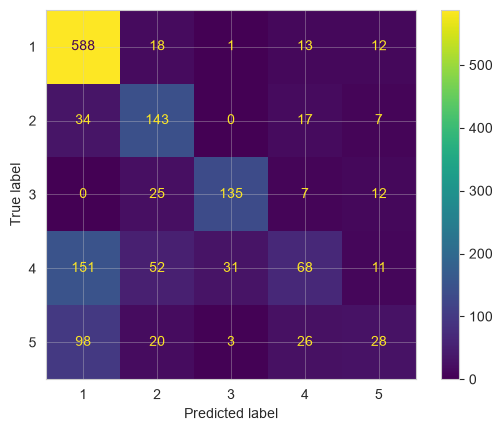

In [46]:
ConfusionMatrixDisplay.from_predictions(y_test, max_depth_tree.predict(X_test))
plt.show()

*Post-Pruning: **ccp_alpha***

In [47]:
ccp_alphas = dt_model.cost_complexity_pruning_path(X_train, y_train)['ccp_alphas']
ccp_alphas

array([0.00000000e+00, 1.90476190e-05, 2.38095238e-05, 3.78151261e-05,
       4.76190476e-05, 6.66666667e-05, 7.14285714e-05, 7.14285714e-05,
       7.61904762e-05, 7.61904762e-05, 8.57142857e-05, 9.52380952e-05,
       9.52380952e-05, 9.52380952e-05, 9.52380952e-05, 9.52380952e-05,
       1.08843537e-04, 1.14285714e-04, 1.22448980e-04, 1.36645963e-04,
       1.39097744e-04, 1.40394089e-04, 1.42857143e-04, 1.58730159e-04,
       1.59663866e-04, 1.61904762e-04, 1.63265306e-04, 1.70068027e-04,
       1.71428571e-04, 1.71428571e-04, 1.71428571e-04, 1.72397220e-04,
       1.74603175e-04, 1.74603175e-04, 1.75824176e-04, 1.77777778e-04,
       1.79271709e-04, 1.80952381e-04, 1.82539683e-04, 1.82857143e-04,
       1.90476190e-04, 1.90476190e-04, 1.90476190e-04, 1.90476190e-04,
       1.90476190e-04, 1.90476190e-04, 1.90476190e-04, 1.90476190e-04,
       1.90476190e-04, 1.90476190e-04, 1.90476190e-04, 1.90476190e-04,
       2.11640212e-04, 2.11640212e-04, 2.11764706e-04, 2.14285714e-04,
      

array([0.00000000e+00, 1.90476190e-05, 2.38095238e-05, 3.78151261e-05,
       4.76190476e-05, 6.66666667e-05, 7.14285714e-05, 7.14285714e-05,
       7.61904762e-05, 7.61904762e-05, 8.57142857e-05, 9.52380952e-05,
       9.52380952e-05, 9.52380952e-05, 9.52380952e-05, 9.52380952e-05,
       1.08843537e-04, 1.14285714e-04, 1.22448980e-04, 1.36645963e-04,
       1.39097744e-04, 1.40394089e-04, 1.42857143e-04, 1.58730159e-04,
       1.59663866e-04, 1.61904762e-04, 1.63265306e-04, 1.70068027e-04,
       1.71428571e-04, 1.71428571e-04, 1.71428571e-04, 1.72397220e-04,
       1.74603175e-04, 1.74603175e-04, 1.75824176e-04, 1.77777778e-04,
       1.79271709e-04, 1.80952381e-04, 1.82539683e-04, 1.82857143e-04,
       1.90476190e-04, 1.90476190e-04, 1.90476190e-04, 1.90476190e-04,
       1.90476190e-04, 1.90476190e-04, 1.90476190e-04, 1.90476190e-04,
       1.90476190e-04, 1.90476190e-04, 1.90476190e-04, 1.90476190e-04,
       2.11640212e-04, 2.11640212e-04, 2.11764706e-04, 2.14285714e-04,
      

In [48]:
estimator_pru.get_params().keys()

dict_keys(['ccp_alpha', 'class_weight', 'criterion', 'max_depth', 'max_features', 'max_leaf_nodes', 'min_impurity_decrease', 'min_samples_leaf', 'min_samples_split', 'min_weight_fraction_leaf', 'monotonic_cst', 'random_state', 'splitter'])

*Hyperparameters to test: **ccp_alpha***

In [49]:
param_grid_pru2 = {'ccp_alpha': [alpha for alpha in ccp_alphas]}
estimator_pru2 = DecisionTreeClassifier(random_state=2022)
ccp_alpha_gs = GridSearchCV(estimator_pru2, param_grid_pru2)

In [50]:
ccp_alpha_gs.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...om_state=2022)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'ccp_alpha': [np.float64(0.0), np.float64(1....047619165e-05), ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0Controls the verbosity o

*Best hyperparameters and best estimator*

In [51]:
ccp_alpha_gs.best_params_

{'ccp_alpha': np.float64(0.0008316875137151618)}

In [52]:
best_ccp_alpha_tree = ccp_alpha_gs.best_estimator_
print(best_ccp_alpha_tree)

DecisionTreeClassifier(ccp_alpha=np.float64(0.0008316875137151618),
                       random_state=2022)


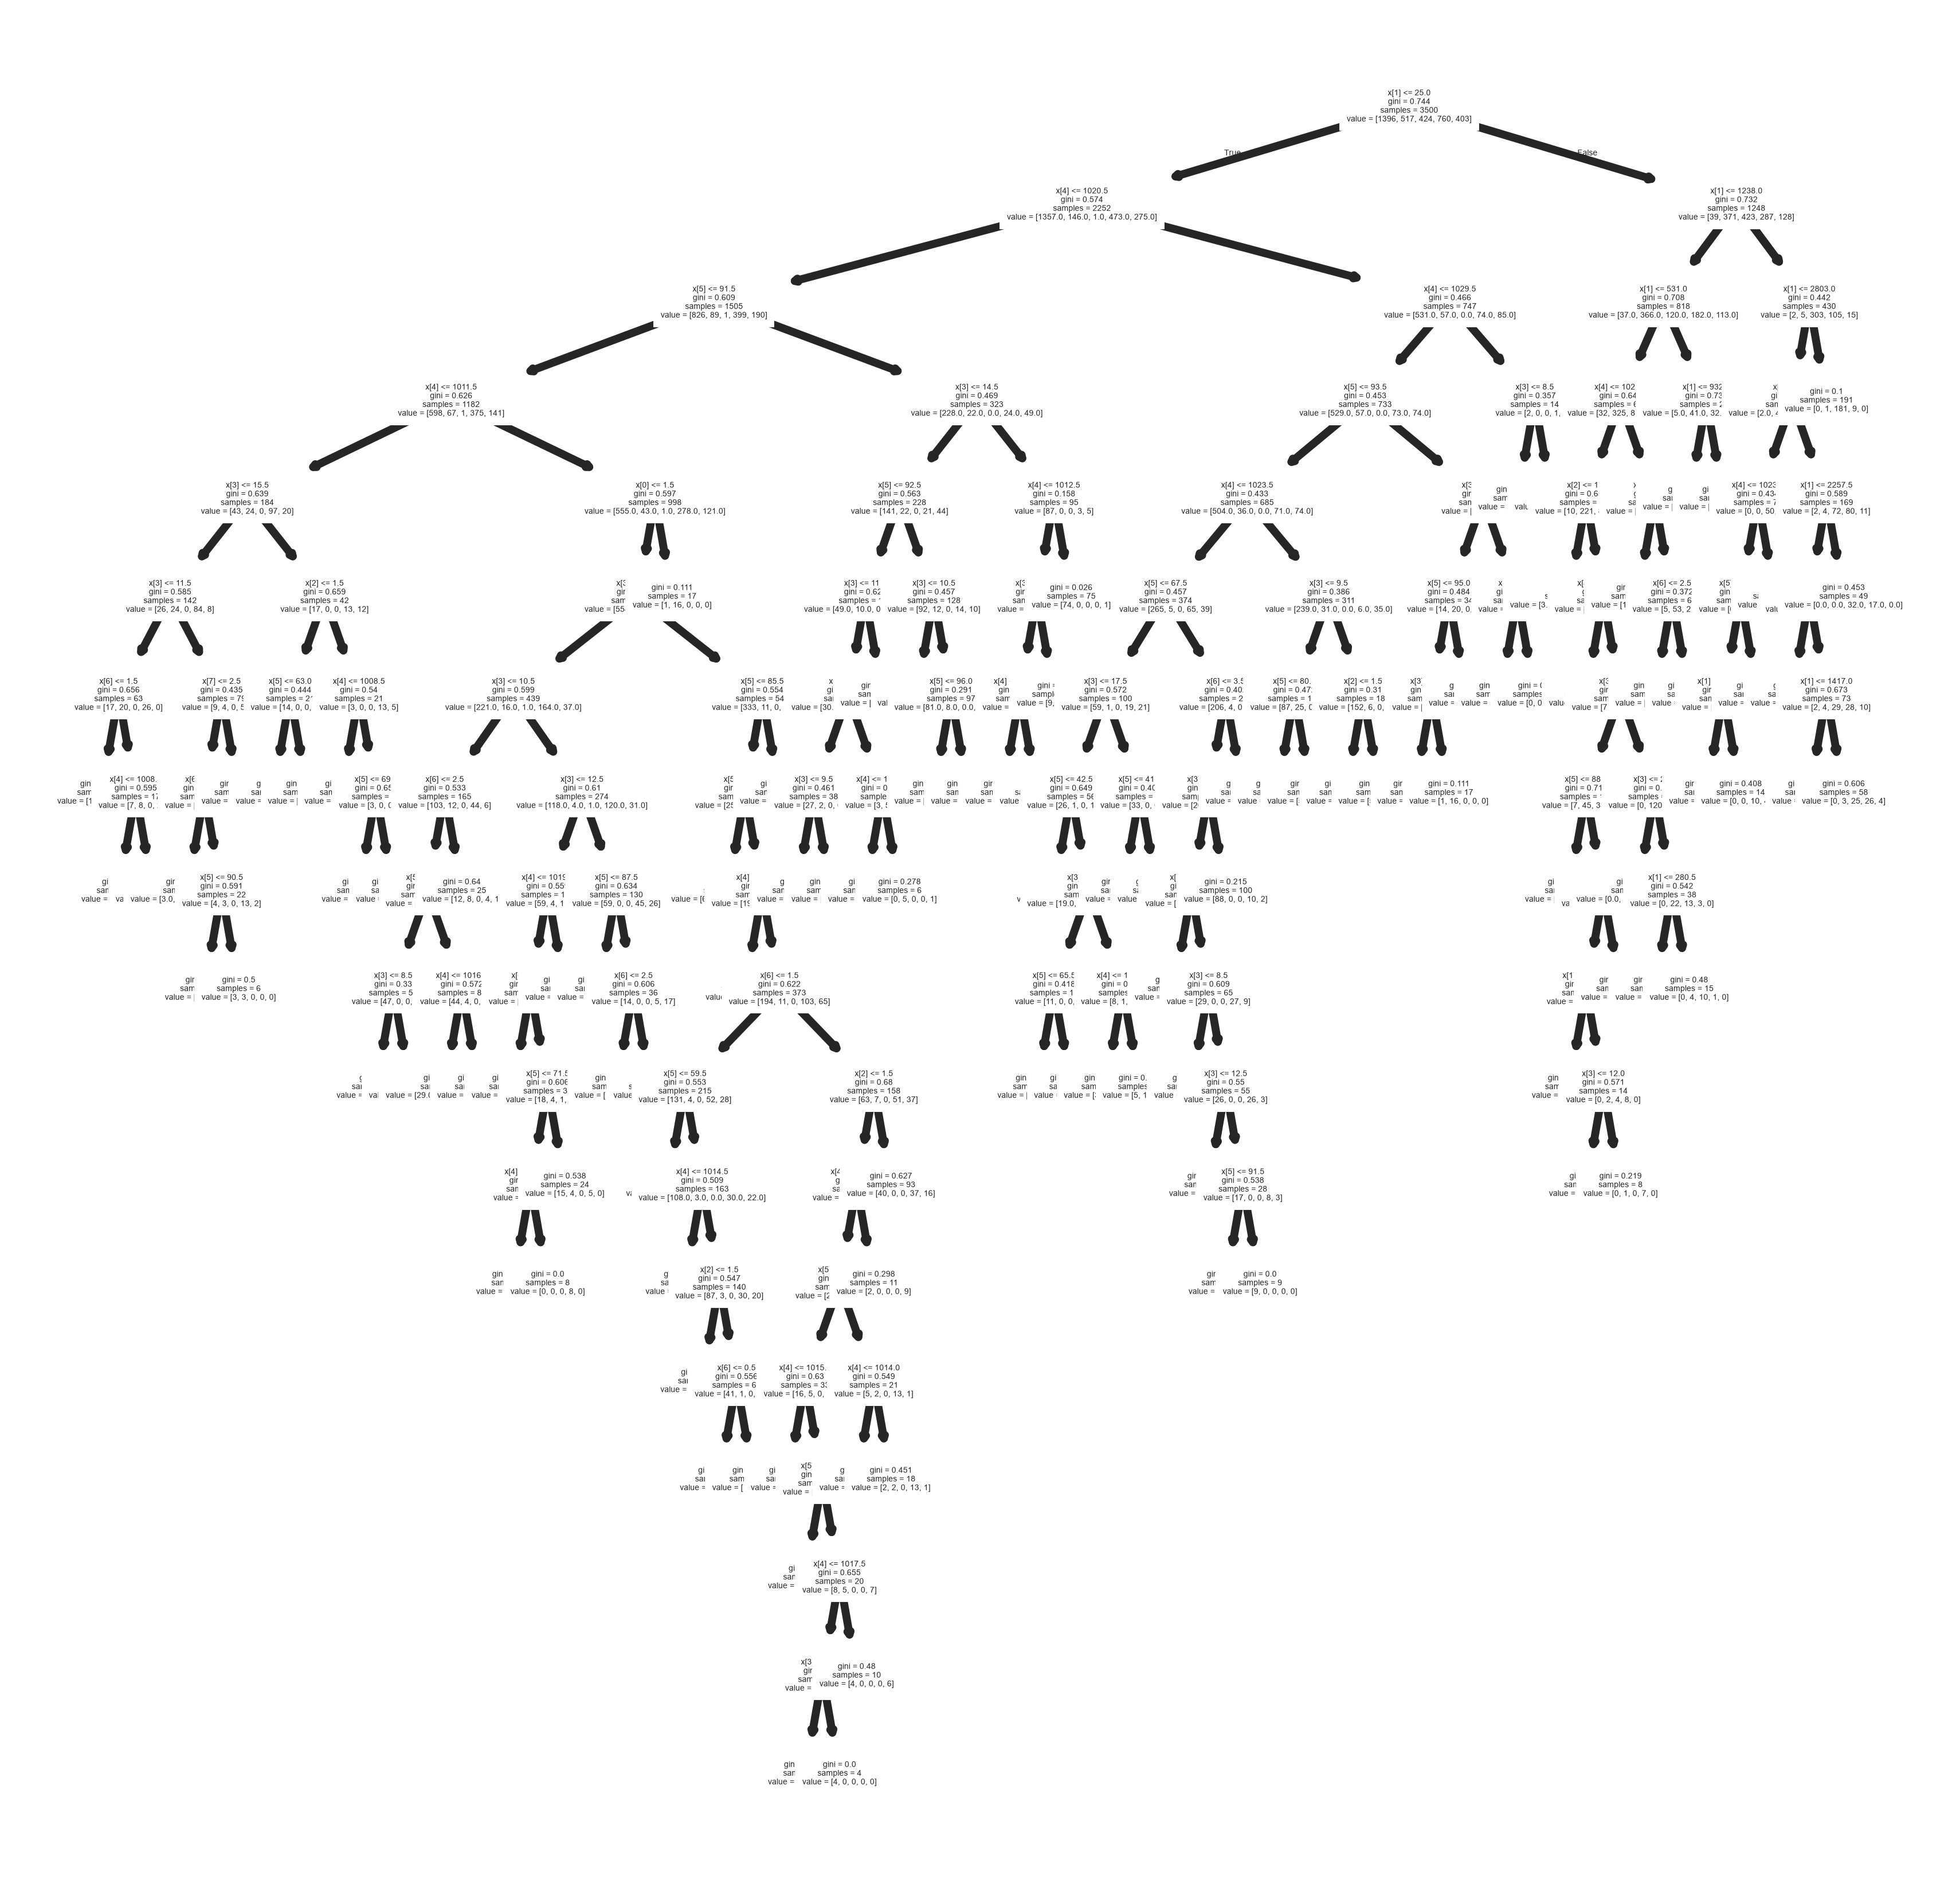

In [53]:
fig = plt.figure(figsize=(4,4), dpi=1000)
tree.plot_tree(best_ccp_alpha_tree)
plt.show()

fig.savefig("dt_plot_alpha.png")

*Model evaluation*

In [54]:
print(classification_report(y_test, best_ccp_alpha_tree.predict(X_test)))

              precision    recall  f1-score   support

           1       0.72      0.82      0.76       632
           2       0.56      0.63      0.59       201
           3       0.78      0.74      0.76       179
           4       0.53      0.33      0.41       313
           5       0.38      0.39      0.39       175

    accuracy                           0.63      1500
   macro avg       0.59      0.58      0.58      1500
weighted avg       0.62      0.63      0.62      1500



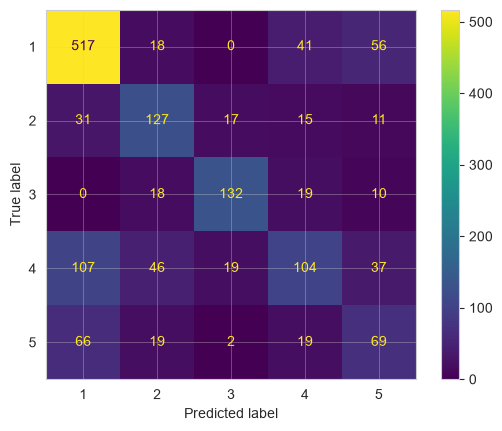

In [55]:
ConfusionMatrixDisplay.from_predictions(y_test, best_ccp_alpha_tree.predict(X_test))
plt.show()

**Hands On**

Try apply GridSearch and Pruning to the Titanic dataset of previous classes.